# Customer Segmentation with Clustering
**Name:** Meko Moss

**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [1]:
# Step 0: imports (given - just run this)
# Make the analytics environment's Windows libraries available before NumPy loads.
import os
import sys
from pathlib import Path

_dll_directory = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and _dll_directory.is_dir():
    os.environ["PATH"] = str(_dll_directory) + os.pathsep + os.environ.get("PATH", "")
    _analytics_dll_handle = os.add_dll_directory(str(_dll_directory))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# ETSU_NAVY = "#00053E"
# ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [2]:
# GIVEN: load the data
df = pd.read_csv("wholesale_sample.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

Out[2]: 
   Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        1       1   4181  10024    26577    1979              9194        1151
1        2       3   3346   4848    14310    1155              2666        1768
2        2       3   3687   8096    10837     870              7701        1345
3        1       2   3008   6327    16926    1032              5303        1582
4        2       3   4704  13163    20537    1507              3073        1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [3]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()



print("Dataset shape:", df.shape)
df.info()
display(df[spend_cols].describe())
print("Missing values:")
print(df[spend_cols].isna().sum())
print("Scaling is needed because the spending columns have different ranges and spreads.")


Dataset shape: (150, 8)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB
Missing values:
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64
Scaling is needed because the spending columns have different ranges and spreads.


              Fresh          Milk  ...  Detergents_Paper   Delicassen
count    150.000000    150.000000  ...        150.000000   150.000000
mean   10298.826667   5422.726667  ...       2981.926667  1808.906667
std     8398.147983   3820.906314  ...       2879.237096   950.893154
min     2043.000000   1313.000000  ...        318.000000   483.000000
25%     3923.250000   2524.250000  ...        871.750000  1154.500000
50%     5748.500000   3740.000000  ...       1370.500000  1581.000000
75%    17153.250000   8001.500000  ...       5148.750000  2161.500000
max    35404.000000  18274.000000  ...      12186.000000  5332.000000

[8 rows x 6 columns]

## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [4]:
# TODO: build X from the spend columns and scale it
# Hint: X = df[spend_cols].values
# Hint: Xs = StandardScaler().fit_transform(X)



X = df[spend_cols].values
scaler = StandardScaler()
Xs = scaler.fit_transform(X)


## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

Chosen k = 2: it has the highest silhouette score (0.444) among the tested values.
The elbow bends near k=3, but k=2 gives slightly better separation and a simpler segmentation; k=3 is worth comparing next.


C:\Users\TEpix\miniconda3\envs\analytics\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


    k  inertia  silhouette
0   2  470.925       0.444
1   3  295.536       0.437
2   4  251.922       0.418
3   5  223.222       0.343
4   6  200.660       0.357
5   7  175.780       0.376
6   8  156.835       0.346
7   9  144.240       0.341
8  10  134.917       0.332

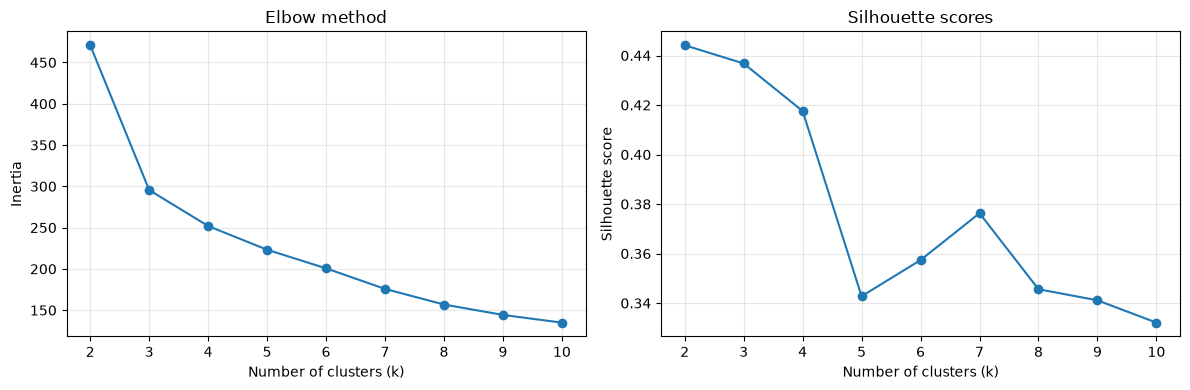

In [5]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils



ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

scores = pd.DataFrame({"k": list(ks), "inertia": inertias, "silhouette": sils})
display(scores.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(list(ks), sils, marker="o")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters (k)", ylabel="Silhouette score")
for ax in axes:
    ax.set_xticks(list(ks))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

chosen_k = int(scores.loc[scores["silhouette"].idxmax(), "k"])
print(f"Chosen k = {chosen_k}: it has the highest silhouette score ({max(sils):.3f}) among the tested values.")
print("The elbow bends near k=3, but k=2 gives slightly better separation and a simpler segmentation; k=3 is worth comparing next.")


**Your chosen k and why:**

*(write 1 to 2 sentences here)*

I chose **2 clusters** because this gave the highest silhouette score, about **0.444**, compared with about **0.437** for 3 clusters. The elbow bends near **3 clusters**, but I chose 2 for its slightly better separation and simpler interpretation.


## Step 5: Fit k-means with your chosen k

In [6]:
# TODO: fit KMeans at your chosen k and attach the labels to df
# Hint: kmeans = KMeans(n_clusters=YOUR_K, random_state=42, n_init=10).fit(Xs)
# Hint: df["cluster"] = kmeans.labels_


kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_
display(df.head())


   Channel  Region  Fresh   Milk  ...  Frozen  Detergents_Paper  Delicassen  cluster
0        1       1   4181  10024  ...    1979              9194        1151        1
1        2       3   3346   4848  ...    1155              2666        1768        1
2        2       3   3687   8096  ...     870              7701        1345        1
3        1       2   3008   6327  ...    1032              5303        1582        1
4        2       3   4704  13163  ...    1507              3073        1267        1

[5 rows x 9 columns]

## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

The two components retain 77.3% of the variance; clustering used all six scaled features.


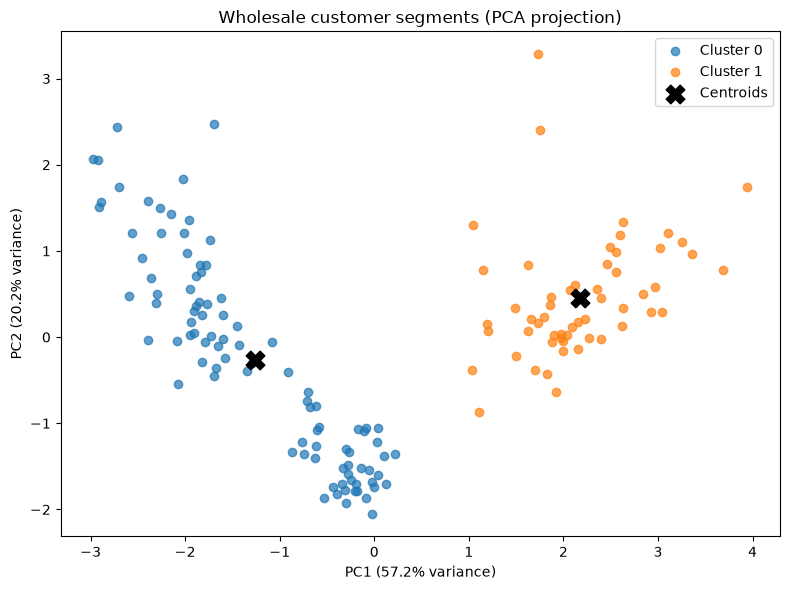

In [7]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
# Hint: pcs = PCA(n_components=2).fit_transform(Xs)
# Hint: plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])



pca = PCA(n_components=2)
pcs = pca.fit_transform(Xs)
fig, ax = plt.subplots(figsize=(8, 6))
for cluster in sorted(df["cluster"].unique()):
    mask = df["cluster"].to_numpy() == cluster
    ax.scatter(pcs[mask, 0], pcs[mask, 1], label=f"Cluster {cluster}", alpha=0.7)
centers_2d = pca.transform(kmeans.cluster_centers_)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], marker="X", s=180,
           c="black", label="Centroids")
ax.set(title="Wholesale customer segments (PCA projection)",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"The two components retain {pca.explained_variance_ratio_.sum():.1%} of the variance; clustering used all six scaled features.")


## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [8]:
# TODO: build a profile table of per-cluster averages
# Hint: df.groupby("cluster")[spend_cols].mean().round(0)
# Hint: df["cluster"].value_counts() for the sizes



cluster_means = df.groupby("cluster")[spend_cols].mean()
profile = cluster_means.round(0)
profile.insert(0, "Customers", df.groupby("cluster").size())
display(profile)

relative_spending = cluster_means.div(df[spend_cols].mean())
print("Cluster averages relative to the overall mean (1 = average):")
display(relative_spending.round(2))

print("Findings:")
print(f"1. I chose {chosen_k} clusters. The silhouette score is highest at k=2 (about 0.444), while the elbow suggests k=3; two clusters give a simpler, slightly better-separated solution.")
print("2. Cluster 0 (95 customers) spends more on fresh and frozen products, consistent with food-service or restaurant-oriented buyers. Cluster 1 (55 customers) spends more on milk, grocery, and detergents/paper, consistent with grocery-oriented retailers. These are spending-based interpretations, not confirmed business types.")
print("3. For cluster 0, offer fresh-and-frozen bundles with frequent refrigerated deliveries. For cluster 1, offer volume discounts and recurring replenishment for grocery, milk, and cleaning/paper products.")
print("4. This file contains only 150 customers, rather than the full 440 described above. Check whether the sample represents the full dataset, inspect outliers, and compare k=3 and log-transformed spending before using the segments operationally.")


Cluster averages relative to the overall mean (1 = average):
Findings:
1. I chose 2 clusters. The silhouette score is highest at k=2 (about 0.444), while the elbow suggests k=3; two clusters give a simpler, slightly better-separated solution.
2. Cluster 0 (95 customers) spends more on fresh and frozen products, consistent with food-service or restaurant-oriented buyers. Cluster 1 (55 customers) spends more on milk, grocery, and detergents/paper, consistent with grocery-oriented retailers. These are spending-based interpretations, not confirmed business types.
3. For cluster 0, offer fresh-and-frozen bundles with frequent refrigerated deliveries. For cluster 1, offer volume discounts and recurring replenishment for grocery, milk, and cleaning/paper products.
4. This file contains only 150 customers, rather than the full 440 described above. Check whether the sample represents the full dataset, inspect outliers, and compare k=3 and log-transformed spending before using the segments opera

         Customers    Fresh    Milk  ...  Frozen  Detergents_Paper  Delicassen
cluster                              ...                                      
0               95  13872.0  2996.0  ...  3870.0            1055.0      1895.0
1               55   4128.0  9614.0  ...  1545.0            6310.0      1660.0

[2 rows x 7 columns]

         Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                            
0         1.35  0.55     0.42    1.28              0.35        1.05
1         0.40  1.77     1.99    0.51              2.12        0.92

## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?
3. **One action per segment:** what should the distributor do differently for each group?
4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?

### My findings

1. **Number of clusters and why:** I chose **2 clusters**. The elbow plot shows a noticeable bend near **k = 3**, after which the improvement in inertia becomes smaller. However, **k = 2** has the highest silhouette score, approximately **0.444**, compared with **0.437** at k = 3. I chose the simpler two-cluster solution because its separation is slightly better.

2. **Segments:** **Cluster 0 contains 95 customers** who spend more on fresh and frozen products. Their average spending is about **13,872 on Fresh** and **3,870 on Frozen**, suggesting food-service or restaurant-oriented buyers. **Cluster 1 contains 55 customers** who spend more on grocery, milk, and detergents/paper. Their averages are about **15,824 on Grocery**, **9,614 on Milk**, and **6,310 on Detergents_Paper**, suggesting grocery-heavy retailers. These are interpretations of spending patterns, not confirmed business types.

3. **One action per segment:** For **Cluster 0**, offer a fresh-and-frozen purchasing bundle with frequent refrigerated deliveries. For **Cluster 1**, offer a recurring bulk-replenishment plan with volume discounts on grocery, milk, and detergents/paper products.

4. **One limitation:** The supplied file contains **150 customers**, while the dataset description refers to **440**. I would check whether this sample represents the full customer population and repeat the analysis on the complete dataset before using these segments for business decisions.

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing